In [29]:
import struct
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

total events: 446248699


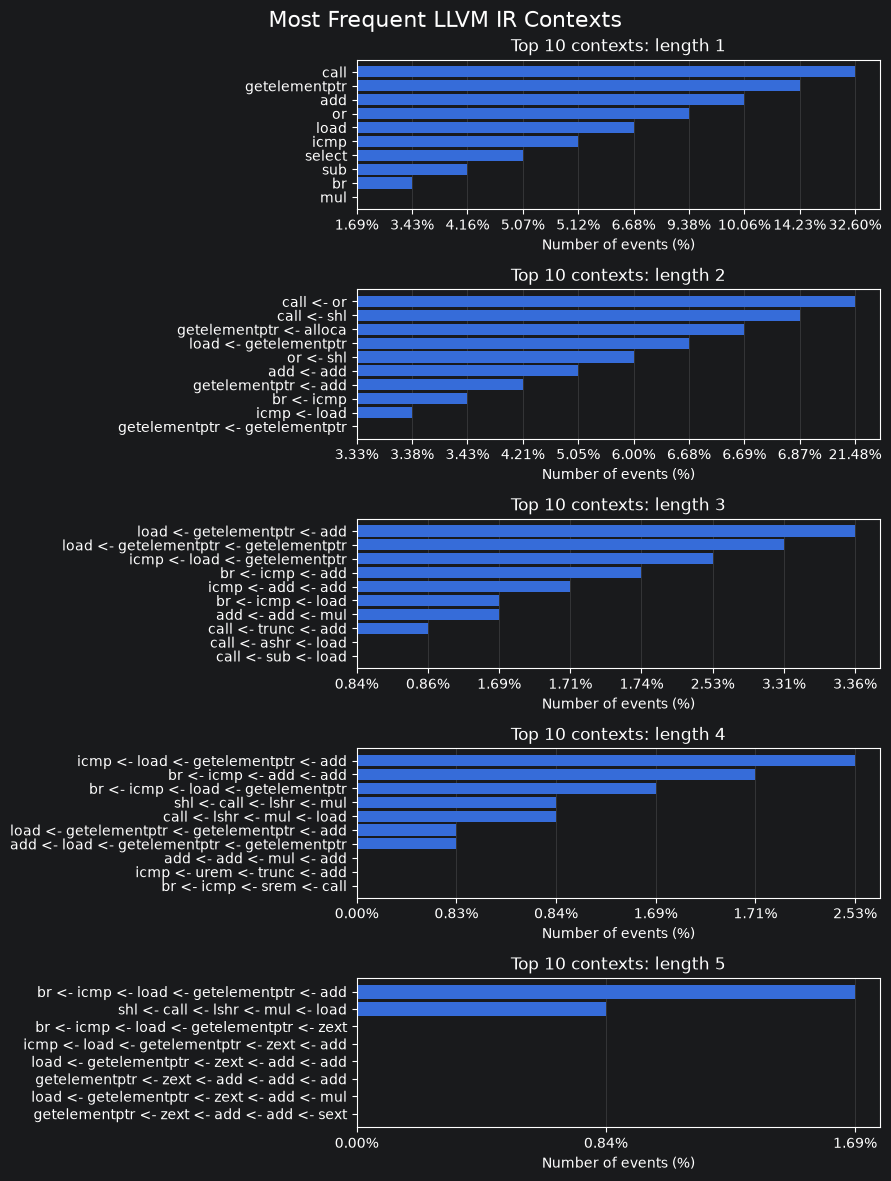

In [30]:
def load_aggregated(fn="llvm_trace_aggregated.bin"):
    with open(fn, "rb") as f:
        total = int(np.fromfile(f, "<u8", 1)[0])
        counters = {}
        for context_len in range(1, 6):
            n = int(np.fromfile(f, "<u4", 1)[0])
            counter = Counter()
            for _ in range(n):
                ops = np.fromfile(f, "<u2", context_len)
                (cnt,) = struct.unpack("Q", f.read(8))
                counter[tuple(int(op) for op in ops)] = cnt
            counters[context_len] = counter
        sym_n = int(np.fromfile(f, "<u4", 1)[0])
        id_to_name = {}
        for _ in range(sym_n):
            op = int(np.fromfile(f, "<u2", 1)[0])
            ln = int(np.fromfile(f, "u1", 1)[0])
            id_to_name[op] = f.read(ln).decode()
    return total, counters, id_to_name

total, counters, id_to_name = load_aggregated()
print(f"total events: {total}")

def chain_label(chain):
    return " <- ".join(
        id_to_name.get(op, f"op_{op}")
        for op in chain
    )

def plot_length(ax, length, top_n=10):
    top = counters[length].most_common(top_n)

    ax.set_title(f"Top {top_n} contexts: length {length}")
    ax.set_xlabel("Number of events (%)")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    labels = [chain_label(chain) for chain, _ in top]
    counts = [count / total for _, count in top]
    percents = [f"{count * 100:.2f}%" for count in counts]

    labels.reverse()
    percents.reverse()

    ax.barh(labels, percents)

fig, axes = plt.subplots(5, 1, figsize=(9, 12))
for length, ax in zip(range(1, 6), axes.flat):
    plot_length(ax, length)

fig.suptitle(
    "Most Frequent LLVM IR Contexts",
    fontsize=16
)

fig.tight_layout()
report_dir = Path("report")
report_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(report_dir / "most_frequent_contexts.png", dpi=200, bbox_inches="tight")
plt.show()
